# 6 · North America: market values, Tobin's Q and investment
Compustat North America also has share prices, which Compustat Global's fundamentals file does not. That makes market-based measures possible for US and Canadian firms:

* **Tobin's Q** ≈ (total assets − book equity + market equity) / total assets. Above 1 means the market values the firm above the book cost of its assets.
* **Market leverage** = debt / (debt + market equity).
* **Altman Z (original, 1968)**, which uses market equity. Below 1.81 is the distress zone.

It then tests the classic investment model: does a firm invest more when its Q is high (investment opportunities) or when its cash flow is high (financing constraints)? Fazzari, Hubbard & Petersen (1988) and later work on the decline of investment-cash flow sensitivity (Chen & Chen, 2012) are the reference points.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


In [2]:
na = p[p.region == "North America"].copy()
na["country"] = na["loc"].map({"USA": "United States", "CAN": "Canada"})
cols = {"tobins_q": "Tobin's Q", "market_leverage": "market leverage", "leverage": "book leverage", "cash": "cash / assets",
        "roa": "operating ROA", "ccc": "cash conversion cycle (days)", "altman_z_market": "Altman Z (market)", "rd": "R&D / sales"}
t = na.groupby("country")[list(cols)].median().rename(columns=cols).T
t.loc["firms"] = na.groupby("country")["gvkey"].nunique()
t.loc["share in Altman distress zone (Z < 1.81) %"] = 100 * na.assign(dz=na.altman_z_market < 1.81).groupby("country")["dz"].mean()
t.round(2)

country,Canada,United States
Tobin's Q,1.30,1.61
market leverage,0.17,0.14
book leverage,0.19,0.22
cash / assets,0.06,0.11
operating ROA,0.02,0.04
cash conversion cycle (days),26.13,50.01
Altman Z (market),1.97,2.65
R&D / sales,0.00,0.00
firms,2521.00,11387.00
share in Altman distress zone (Z < 1.81) %,41.17,31.76


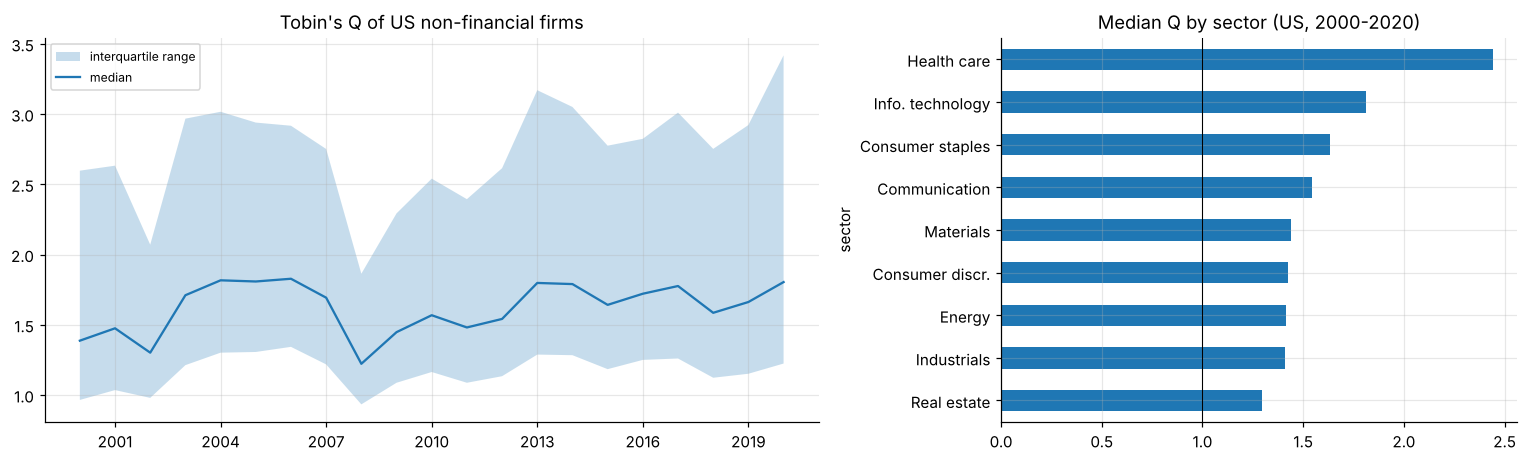

fyear,2000,2002,2007,2009,2019,2020
0.25,0.97,0.98,1.22,1.09,1.15,1.22
0.50,1.39,1.30,1.69,1.45,1.66,1.80
0.75,2.60,2.07,2.75,2.29,2.92,3.42


In [3]:
sec_names = {10: "Energy", 15: "Materials", 20: "Industrials", 25: "Consumer discr.", 30: "Consumer staples", 35: "Health care",
             45: "Info. technology", 50: "Communication", 60: "Real estate"}
us = na[na["loc"] == "USA"]
qy = us.groupby("fyear")["tobins_q"].quantile([0.25, 0.5, 0.75]).unstack()
qs = us.assign(sector=us.gsector.map(sec_names)).groupby("sector")["tobins_q"].median().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].fill_between(qy.index, qy[0.25], qy[0.75], alpha=0.25, label="interquartile range"); ax[0].plot(qy.index, qy[0.5], label="median")
ax[0].set_title("Tobin's Q of US non-financial firms"); ax[0].legend(fontsize=8); int_years(ax[0])
qs.plot.barh(ax=ax[1], color="C0"); ax[1].set_title("Median Q by sector (US, 2000-2020)"); ax[1].axvline(1, color="k", lw=0.7)
plt.tight_layout(); plt.savefig(IMG / "us_tobins_q.png", bbox_inches="tight"); plt.show()
qy.round(2).T[[2000, 2002, 2007, 2009, 2019, 2020]]

## Does investment follow Q or cash flow?
Investment (capex / last year's net PP&E) in year *t* is regressed on Tobin's Q at the end of *t − 1* and cash flow (income before extraordinary items + depreciation, also over last year's PP&E) in *t*, with firm and year fixed effects. The sample is US firms with at least USD 10m of assets and PP&E of at least 5% of assets, since the ratios are meaningless for firms with almost no fixed assets. It is run for all such firms, by size (below and above median assets) and for 2001-2009 against 2010-2020.

In [4]:
u = us.sort_values(["gvkey", "fyear"]).copy()
g = u.groupby("gvkey"); cont = g["fyear"].diff() == 1
u["q_lag"] = g["tobins_q"].shift(1).where(cont); u["ppe_lag"] = g["tangibility"].shift(1).where(cont)    # PP&E / assets, last year
u = u[(u.ppe_lag >= 0.05) & (u.at_usd >= 10)].copy()
u["investment"] = u.capex / u.ppe_lag; u["cf_k"] = u.cash_flow / u.ppe_lag                                   # both relative to last year's PP&E
for c in ["investment", "cf_k"]: u[c] = u[c].clip(u[c].quantile(0.01), u[c].quantile(0.99))
u["large"] = u["size"] >= u.groupby("fyear")["size"].transform("median")
specs = {"all firms": u, "small firms": u[~u.large], "large firms": u[u.large], "2001-2009": u[u.fyear <= 2009], "2010-2020": u[u.fyear >= 2010]}
rows = {}
for name, d in specs.items():
    res = regress.fe(d, "investment", ["q_lag", "cf_k"])
    rows[name] = {"Q coef": res.loc["q_lag", "coef"], "Q t": res.loc["q_lag", "t"], "cash-flow coef": res.loc["cf_k", "coef"],
                  "cash-flow t": res.loc["cf_k", "t"], "firm-years": res.attrs["nobs"], "within R²": res.attrs["r2_within"]}
inv = pd.DataFrame(rows).T
inv.round(4).to_csv(DATA / "us_investment_q_fe.csv")
inv.assign(**{c: inv[c].map(lambda v: f"{v:.4f}") for c in ["Q coef", "cash-flow coef", "within R²"]}).assign(**{c: inv[c].round(1) for c in ["Q t", "cash-flow t"]}, **{"firm-years": inv["firm-years"].astype(int)})

,Q coef,Q t,cash-flow coef,cash-flow t,firm-years,within R²
all firms,0.0158,10.6,-0.0102,-7.9,52359,0.0299
small firms,0.0129,7.7,-0.0121,-8.1,26361,0.0278
large firms,0.0226,9.5,-0.0003,-0.1,25998,0.0412
2001-2009,0.0167,7.7,-0.0129,-7.5,27682,0.0379
2010-2020,0.0136,5.0,-0.0117,-5.1,24677,0.0185


In [5]:
ok = us[["altman_z_market", "z_score"]].dropna()
agree = pd.crosstab(pd.cut(ok.altman_z_market, [-np.inf, 1.81, 2.99, np.inf], labels=["distress", "grey", "safe"]),
                    pd.cut(ok.z_score, [-np.inf, 1.1, 2.6, np.inf], labels=["distress", "grey", "safe"]), normalize="all") * 100
agree.index.name = "Altman Z (market, 1968)"; agree.columns.name = "Altman Z'' (book, 1995)"
print(f"Agreement on the zone: {np.trace(agree.to_numpy()):.0f}% of {len(ok):,} US firm-years")
agree.round(1)

Agreement on the zone: 75% of 80,954 US firm-years


"Altman Z'' (book, 1995)",distress,grey,safe
"Altman Z (market, 1968)",,,
distress,32.1,4.8,1.4
grey,3.2,5.4,7.9
safe,4.5,3.4,37.3


## Findings
* **US firms are valued higher, hold more cash and run tighter working capital than Canadian firms.** The median Tobin's Q is 1.61 vs 1.30, cash is 11% vs 6% of assets, operating ROA 4% vs 2%, and the cash conversion cycle 50 vs 26 days (Canada's is shorter because of its resource and energy weighting). 41% of Canadian firm-years fall in the Altman distress zone against 32% for the USA, reflecting the many small mining and energy companies listed in Canada.
* **Valuations are cyclical and widening.** The median US Q fell from 1.39 (2000) to 1.30 (2002), peaked at 1.69 in 2007, dropped to 1.22 in 2008, and reached 1.80 in 2020. The upper quartile rose from 2.6 to 3.4, so the gap between high- and low-valued firms has grown. Health care (2.4) and IT (1.8) have the highest median Q, real estate and industrials the lowest.
* **Investment follows Q, especially for large firms.** A one-unit higher Q goes with capex 1.6% of PP&E higher the next year (t = 10.6), and 2.3% for large firms.
* **Cash flow no longer predicts investment.** The cash-flow coefficient is negative for small firms (-0.012, t = -8) and zero for large ones, in both 2001-2009 and 2010-2020. The classic financing-constraint signal of Fazzari et al. (1988) has disappeared in modern US data, consistent with Chen & Chen (2012). Many small firms invest while burning cash, funded by equity.
* **Book-based and market-based distress scores agree 75% of the time.** The original Altman Z (with market equity) and Z'' (book only) place 75% of US firm-years in the same zone. The book-only version is therefore a reasonable substitute in countries without reliable market prices, as in the global notebooks.